# 03 — Credit Risk Model Training

## Objective
Train and compare Logistic Regression, Random Forest, and XGBoost models to estimate the probability of default.

All preprocessing is embedded in sklearn pipelines to prevent fitting imputation, scaling, or encoding on the holdout data.

In [1]:
import os, sys, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

## 1. Train models

In [3]:
%pip install xgboost

   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   -- ------------------------------------- 3.1/48.9 MB 23.1 MB/s eta 0:00:02
   -------- ------------------------------- 10.0/48.9 MB 29.6 MB/s eta 0:00:02
   ------------- -------------------------- 17.0/48.9 MB 30.7 MB/s eta 0:00:02
   ------------------- -------------------- 23.9/48.9 MB 31.5 MB/s eta 0:00:01
   ------------------------ --------------- 29.6/48.9 MB 30.3 MB/s eta 0:00:01
   ----------------------------- ---------- 35.7/48.9 MB 30.2 MB/s eta 0:00:01
   --------------------------------- ------ 40.9/48.9 MB 29.6 MB/s eta 0:00:01
   ------------------------------------ --- 44.6/48.9 MB 27.8 MB/s eta 0:00:01
   ---------------------------------------  48.2/48.9 MB 26.5 MB/s eta 0:00:01
   ---------------------------------------  48.8/48.9 MB 26.3 MB/s eta 0:00:01
   ---------------------------------------- 48.9/48.9 MB 21.9 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packag

In [4]:
from src.train import train_all
comparison = train_all(
    data_dir=PROJECT_ROOT / "data" / "raw",
    model_dir=PROJECT_ROOT / "models",
    report_dir=PROJECT_ROOT / "reports"
)
display(comparison)

Logistic Regression: ROC-AUC=0.7487
Random Forest: ROC-AUC=0.7744
XGBoost: ROC-AUC=0.7812


,model,roc_auc,average_precision
2,XGBoost,0.781202,0.563622
1,Random Forest,0.774350,0.554493
0,Logistic Regression,0.748682,0.509949


## 2. Compare ROC-AUC

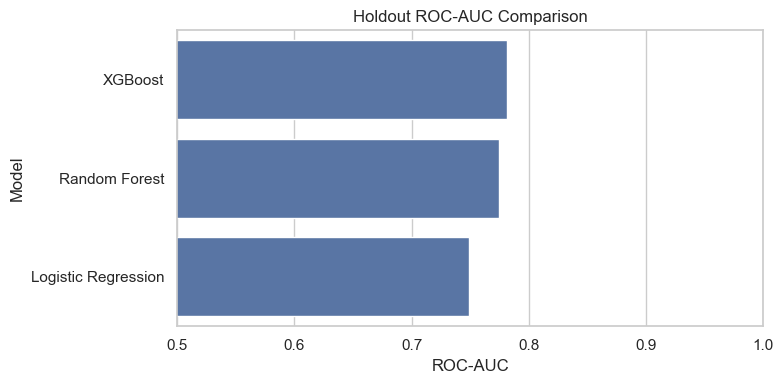

In [5]:
plt.figure(figsize=(8, 4))
sns.barplot(data=comparison, x="roc_auc", y="model")
plt.xlim(0.5, 1.0)
plt.title("Holdout ROC-AUC Comparison")
plt.xlabel("ROC-AUC")
plt.ylabel("Model")
plt.tight_layout()
plt.savefig(PROJECT_ROOT / "reports" / "model_training_auc.png", dpi=200)
plt.show()

## 3. Select a candidate model

The model with the highest holdout ROC-AUC is only a candidate, not automatically the production winner. Review calibration, KS, stability, explainability, operational constraints, and validation evidence before selection.

In [6]:
best_row = comparison.sort_values("roc_auc", ascending=False).iloc[0]
print("Highest ROC-AUC candidate:", best_row["model"])
print("ROC-AUC:", round(best_row["roc_auc"], 4))

Highest ROC-AUC candidate: XGBoost
ROC-AUC: 0.7812
